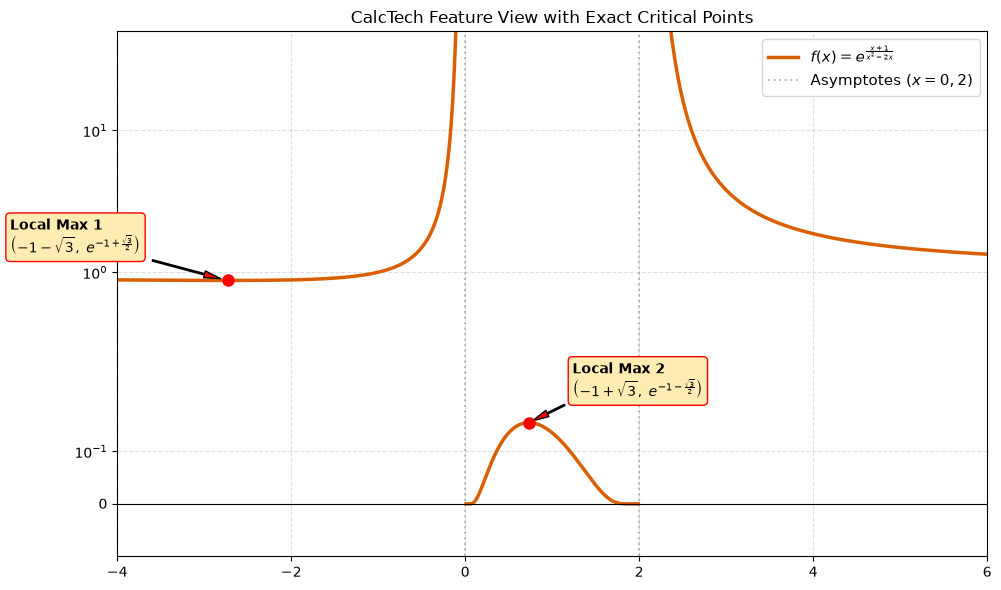

In [1]:
# f(x) = e^x, g(x) = (x+1)/(x^2 - 2x), y = f(g(x))그래프 그리는 프로그램
import numpy as np
import matplotlib.pyplot as plt
# 다크 테마 대신 기본 테마(흰 배경) 적용
plt.style.use('default')
# 1. 구간 분할 (점근선 x=0, 2 회피)
x1 = np.linspace(-4, -0.01, 500)
x2 = np.linspace(0.01, 1.99, 500)
x3 = np.linspace(2.01, 10, 500)

def f(x):
    return np.exp((x + 1) / (x**2 - 2*x)) #함수 정의
#각 구간별 Y 데이터 샘플링
y1, y2, y3 = f(x1), f(x2), f(x3)

# 2. 정확한 극값 (Exact Values) 위치 계산
#방정식 y' = 0의 근
x_max1 = -1 - np.sqrt(3)  # ≈ -2.732, 좌측 극대
y_max1 = f(x_max1)

x_max2 = -1 + np.sqrt(3)  # ≈ 0.732, 중앙 극대
y_max2 = f(x_max2)

# 3. 뷰포트, 캔버스 랜더링 엔진
fig, ax = plt.subplots(figsize=(10, 6))

# 4. 메인 곡선 드로잉 (연속성이 깨지는 점근선 구간은 분리해서 그림)
ax.plot(x1, y1, color='#d95f02', lw=2.5, label=r'$f(x) = e^{\frac{x+1}{x^2-2x}}$')
ax.plot(x2, y2, color='#d95f02', lw=2.5)
ax.plot(x3, y3, color='#d95f02', lw=2.5)

# Y축 스케일 조정 (개형 강조용)
#symlog: 0근처는 선형, 절댓값이 0.3 이상이면 로그 스케일 적용
ax.set_yscale('symlog', linthresh=0.3)

# 점근선 처리 (투명 점선)
ax.axvline(0, color='gray', linestyle=':', alpha=0.5, lw=1.5, label='Asymptotes ($x=0, 2$)')
ax.axvline(2, color='gray', linestyle=':', alpha=0.5, lw=1.5) #':' 점선, '--' 파선, '-' 실선
#alpha: 투명도, lw: 선의 굵기

# [극대점 1] x = -1 - sqrt(3), y = e^(-1 + sqrt(3)/2)
# zorder: 렌더링 레이어 순서 (높을수록 위에 그려지고 없으면 그래프에 뭍혀서 안보여질 수 있음.)
ax.plot(x_max1, y_max1, 'ro', markersize=8, zorder=5)
ax.annotate(r'Local Max 1' + '\n' + r'$\left(-1-\sqrt{3},\; e^{-1+\frac{\sqrt{3}}{2}}\right)$',
             xy=(x_max1, y_max1),
             xytext=(x_max1 - 2.5, y_max1 + 0.5),
             arrowprops=dict(facecolor='red', shrink=0.08, width=1, headwidth=5),
             fontsize=10, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.3", fc="#ffecb3", ec="red", lw=1))

# [극대점 2] x = -1 + sqrt(3), y = e^(-1 - sqrt(3)/2)
ax.plot(x_max2, y_max2, 'ro', markersize=8, zorder=5)
ax.annotate(r'Local Max 2' + '\n' + r'$\left(-1+\sqrt{3},\; e^{-1-\frac{\sqrt{3}}{2}}\right)$',
             xy=(x_max2, y_max2),
             xytext=(x_max2 + 0.5, y_max2 + 0.05),
             arrowprops=dict(facecolor='red', shrink=0.08, width=1, headwidth=5),
             fontsize=10, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.3", fc="#ffecb3", ec="red", lw=1))

#5. 뷰포트 클리핑 및 격자 설정
ax.set_xlim(-4, 6)
ax.set_ylim(-0.1, 50)
ax.axhline(0, color='black', linewidth=0.8)
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper right', fontsize=11)
ax.set_title("CalcTech Feature View with Exact Critical Points", fontsize=12)

plt.tight_layout()
plt.show()

#C언어 변환시 고려해야할 부분
#1. 불연속 구간 (e.g. 점근선, 정의가 안된 구간) 데이터 구조화
#2. x,y축의 눈금 자동 보정 알고리즘

<>:28: SyntaxWarning: invalid escape sequence '\p'
<>:28: SyntaxWarning: invalid escape sequence '\p'
C:\Users\redbl\AppData\Local\Temp\ipykernel_19332\506086366.py:28: SyntaxWarning: invalid escape sequence '\p'
  ax.plot(x_period, y_period, color='#ff5722', lw=3.5, zorder=4, label='Highlighted Period ($T=\pi$)')


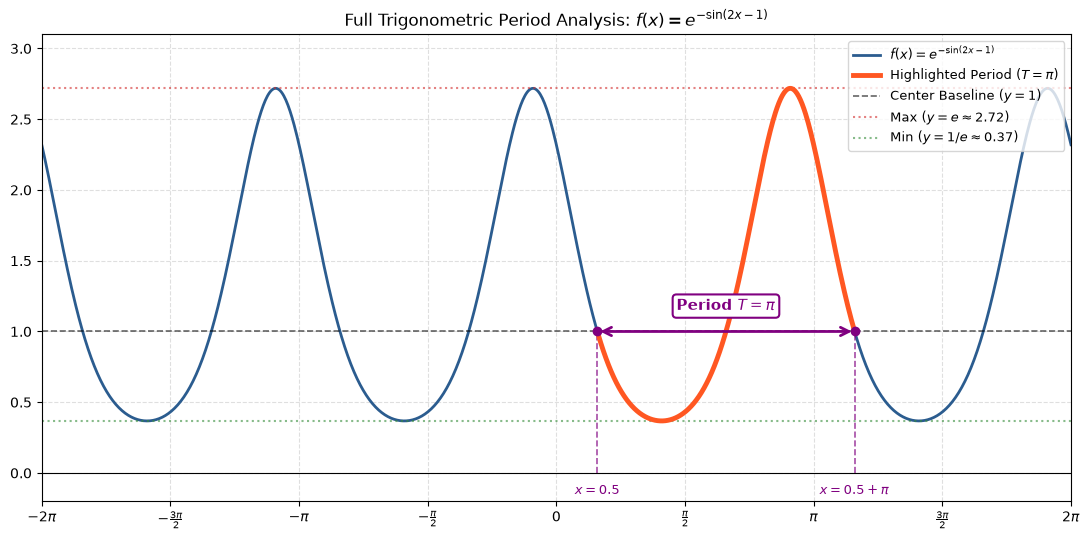

In [2]:
## 정의역을 파이 단위로 쪼갠 삼각함수 그래프
#f(x) = e^(-sin(2x-1))
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. 함수 정의 및 기본 데이터 생성
def f(x):
    return np.exp(-np.sin(2 * x - 1))

# 전체 x 범위 (-2pi ~ 2pi)
x_full = np.linspace(-2 * np.pi, 2 * np.pi, 1000)
y_full = f(x_full)

# 한 주기 하이라이트 구간 설정 (x_start = 0.5, x_end = 0.5 + pi)
x_start = 0.5 #sin(2x-1)에서 괄호안의 값이 0이 되는 점 (쉽게말해, 함수의 시작점)
x_end = 0.5 + np.pi #주기: pi
x_period = np.linspace(x_start, x_end, 300)
y_period = f(x_period)

fig, ax = plt.subplots(figsize=(11, 5.5))

# 2. 그래프 그리기
# (1) 전체 그래프 (기본 파란색)
ax.plot(x_full, y_full, color='#2b5c8f', lw=2, label=r'$f(x) = e^{-\sin(2x-1)}$')

# (2) 한 주기 강조 그래프 (눈에 띄는 주황/레드 계열로 덮어씌우기)
ax.plot(x_period, y_period, color='#ff5722', lw=3.5, zorder=4, label='Highlighted Period ($T=\pi$)')

# 3. 주요 기준선 및 경계선
# y=1 중심선 (x축 역할)
ax.axhline(1, color='black', linestyle='--', alpha=0.6, lw=1.2, label='Center Baseline ($y=1$)')

# 최댓값(y = e), 최솟값(y = 1/e) 점선
ax.axhline(np.e, color='#d32f2f', linestyle=':', alpha=0.6, lw=1.5, label=r'Max ($y=e \approx 2.72$)')
ax.axhline(1/np.e, color='#388e3c', linestyle=':', alpha=0.6, lw=1.5, label=r'Min ($y=1/e \approx 0.37$)')

# 4. 주기 표시 화살표 & 수선의 발 (x축으로 그어지는 점선)
# 양방향 화살표
ax.annotate('', xy=(x_start, 1), xytext=(x_end, 1),
            arrowprops=dict(arrowstyle='<->', color='purple', lw=2, mutation_scale=15), zorder=5)

# 화살표 중앙 주기 텍스트
ax.text((x_start + x_end) / 2, 1.15, r'Period $T = \pi$', 
        fontsize=11, color='purple', fontweight='bold', ha='center',
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="purple", lw=1.5), zorder=6)

# 양쪽 끝점에서 x축으로 내리는 수선의 발 (수직 점선)
ax.vlines(x=[x_start, x_end], ymin=0, ymax=1, color='purple', linestyle='--', alpha=0.7, lw=1.2, zorder=3)

# 수선의 발 x축 좌표 텍스트 레이블 (0.5, 0.5 + \pi)
ax.text(x_start, -0.15, r'$x = 0.5$', color='purple', fontweight='bold', fontsize=9.5, ha='center')
ax.text(x_end, -0.15, r'$x = 0.5 + \pi$', color='purple', fontweight='bold', fontsize=9.5, ha='center')

# 끝점 위치 강조 마커 (y=1 교점)
ax.plot([x_start, x_end], [1, 1], 'o', color='purple', markersize=6, zorder=6)

# 5. x축 pi 단위 커스텀 포멧터
def pi_formatter(x, pos): #pos인자는 인터페이스 규칙상 필수 매개벼수
    fraction = x / np.pi
    if np.isclose(fraction, 0): return "$0$"
    elif np.isclose(fraction, 1): return r"$\pi$"
    elif np.isclose(fraction, -1): return r"$-\pi$" #현재 눈금 위치(fraction)가 파이의 몇배인지 파악하는 코드
    elif np.isclose(fraction, 0.5): return r"$\frac{\pi}{2}$" #만약 Fraction = 1.0이라고 쓰면 계산오차때문에 지저분하게 출력
    elif np.isclose(fraction, -0.5): return r"$-\frac{\pi}{2}$" 
    elif fraction.is_integer(): return f"${int(fraction)}" + r"\pi$"
    else: #위의 코드블록 이외의 눈금들을 처리하는 안전망 (위의 숫자가 아니더라도 0.5파이 단위로 눈금 표시)
        from fractions import Fraction
        frac = Fraction(fraction).limit_denominator(4) 
        #소수점 변환시 생기는 오차로 인해 발생한 지저분한 수를 깔끔한 수로 정리
        if frac.numerator < 0:
            return rf"$-\frac{{{abs(frac.numerator)}\pi}}{{{frac.denominator}}}$"
        else:
            return rf"$\frac{{{frac.numerator}\pi}}{{{frac.denominator}}}$"

ax.xaxis.set_major_locator(ticker.MultipleLocator(np.pi / 2))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(pi_formatter))
#괄호를 안붙이고 이름만 넘기는건 함수 자체를 인자로 전달하는 분법

# 6. 여백 및 스타일 정리
ax.set_xlim(-2 * np.pi, 2 * np.pi)
ax.set_ylim(-0.2, 3.1)
ax.axhline(0, color='black', linewidth=0.8)  # 진짜 x축 강조
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper right', fontsize=9.5)
ax.set_title(r"Full Trigonometric Period Analysis: $f(x) = e^{-\sin(2x-1)}$", fontsize=12)

plt.tight_layout()
plt.show()

#C언어로 정리할떄 고려할점
#1. 1번 코드와 일맥상통 하겠지만, 눈금의 단위를 파이로 바꿀 기준 세우기. (단위 정규화)
#e.g. y = pix -> y축만 pi, y = sinpix -> x,y축 둘다 pi필요X
#2. 분.소수 계산기 생기는 부동소수점 오차 보정 (수치적 오차 정제)

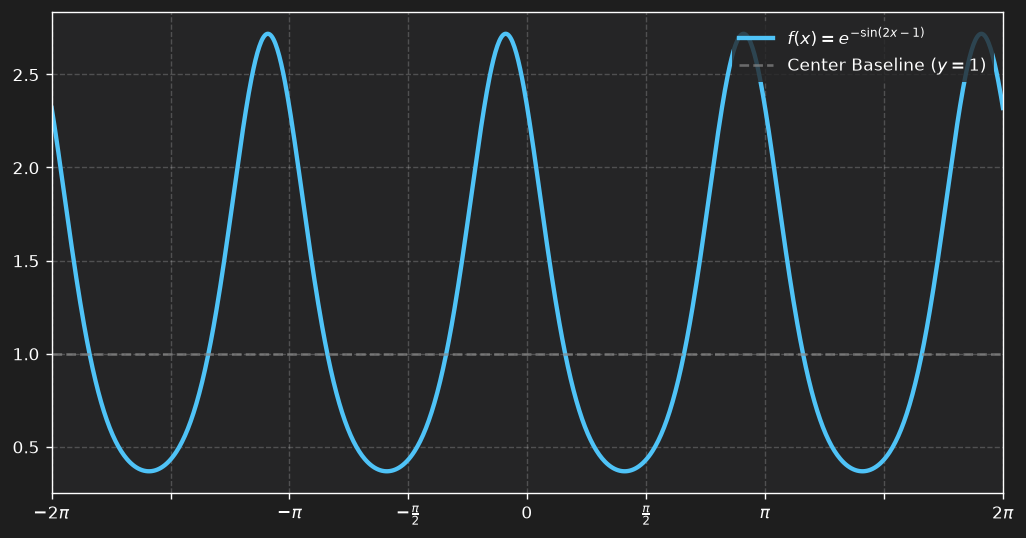

In [14]:
#pyqt6에서 나온 이미지를 모던(?)하게 바꾸기
#나중에 쓸땐 복붙 ㄱㄱ

#FigureCanvasQTAgg 클래스: matplotlib가 그린 그래프를 pyqt6가 이해할 수 있도록 변환해주는 어댑터
#layout.addWidget(canvas) 메소드: 창 크기를 건들때 그래프도 같이 변하게 해줌.
%gui qt6

import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
from PyQt6.QtWidgets import QApplication, QMainWindow, QVBoxLayout, QWidget, QLabel
from PyQt6.QtCore import Qt

class ModernGraphApp(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle("CalcTech - Modern Graph Engine View")
        self.setGeometry(100, 100, 1000, 600)

        # 모던 다크 테마 QSS 스타일시트
        self.setStyleSheet("""
            QMainWindow { background-color: #1e1e1e; }
            QLabel {
                color: #ffffff;
                font-family: 'Segoe UI', sans-serif;
                font-size: 16px;
                font-weight: bold;
                padding: 10px;
            }
        """)

        main_widget = QWidget()
        self.setCentralWidget(main_widget)
        layout = QVBoxLayout(main_widget)

        title_label = QLabel("CalcTech Trigonometric Canvas Pipeline")
        title_label.setAlignment(Qt.AlignmentFlag.AlignCenter)
        layout.addWidget(title_label)

        # Matplotlib 다크 스타일 설정
        plt.style.use('dark_background')
        self.fig, self.ax = plt.subplots(figsize=(10, 5), facecolor='#1e1e1e')
        self.ax.set_facecolor('#252526')

        self.canvas = FigureCanvas(self.fig)
        layout.addWidget(self.canvas)

        self.plot_graph()

    def plot_graph(self):
        x = np.linspace(-2 * np.pi, 2 * np.pi, 1000)
        y = np.exp(-np.sin(2 * x - 1))

        self.ax.plot(x, y, color='#4fc3f7', lw=2.5, label=r'$f(x) = e^{-\sin(2x-1)}$')
        self.ax.axhline(1, color='#888888', linestyle='--', alpha=0.7, label='Center Baseline ($y=1$)')

        def pi_formatter(val, pos):
            frac = val / np.pi
            if np.isclose(frac, 0): return "$0$"
            elif np.isclose(frac, 1): return r"$\pi$"
            elif np.isclose(frac, -1): return r"$-\pi$"
            elif np.isclose(frac, 0.5): return r"$\frac{\pi}{2}$"
            elif np.isclose(frac, -0.5): return r"$-\frac{\pi}{2}$"
            elif frac.is_integer(): return f"${int(frac)}" + r"\pi$"
            return ""

        self.ax.xaxis.set_major_locator(ticker.MultipleLocator(np.pi / 2))
        self.ax.xaxis.set_major_formatter(ticker.FuncFormatter(pi_formatter))

        self.ax.set_xlim(-2 * np.pi, 2 * np.pi)
        self.ax.grid(True, linestyle='--', alpha=0.2, color='#ffffff')
        self.ax.legend(loc='upper right', facecolor='#252526', edgecolor='none')
        
        self.canvas.draw()

# 주피터 환경에서는 QApplication 인스턴스가 이미 존재하는지 체크
app = QApplication.instance()
if app is None:
    app = QApplication(sys.argv)

window = ModernGraphApp()
window.show()

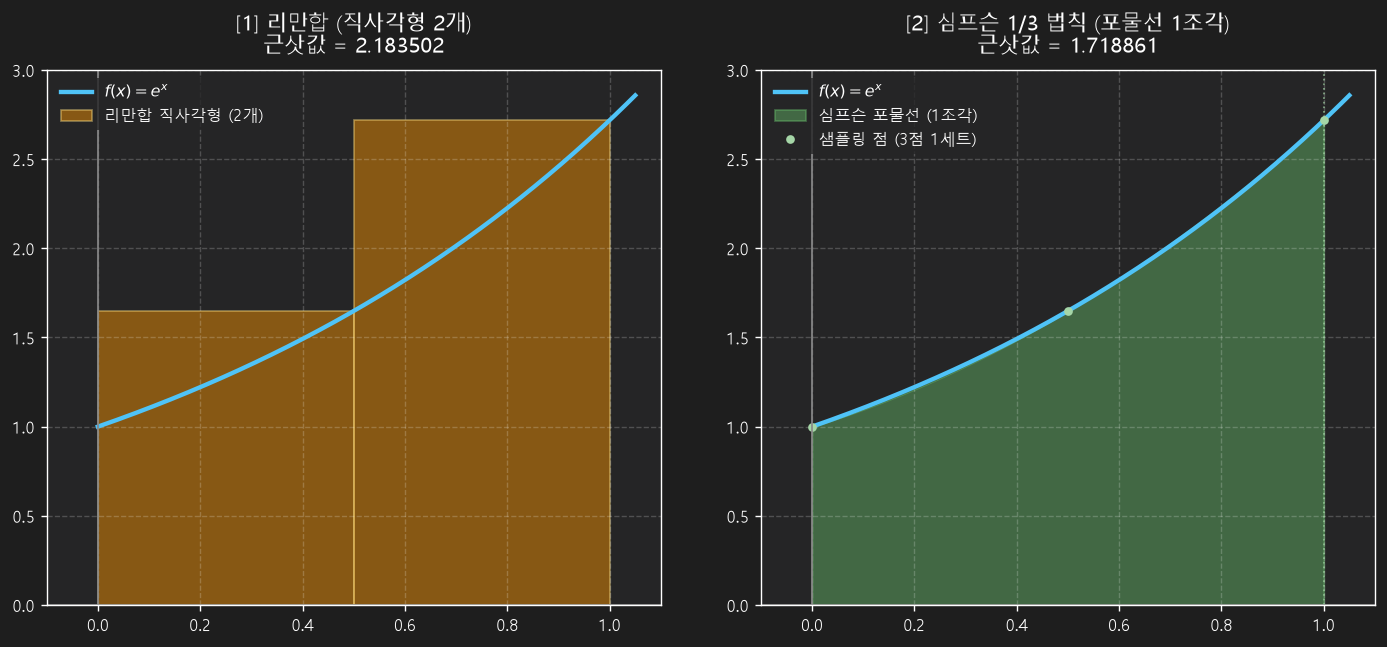

In [1]:
%gui qt6

import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
from PyQt6.QtWidgets import (QApplication, QMainWindow, QVBoxLayout, 
                             QHBoxLayout, QWidget, QLabel, QSlider, QPushButton, QSizePolicy)
from PyQt6.QtCore import Qt, QTimer

class InteractiveRiemannVsSimpsonApp(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle("CalcTech - Riemann Sum vs Simpson's 1/3 Rule Simulator")
        self.setGeometry(100, 100, 1200, 650)

        # 1. 타이머 생성 (자동 재생용)
        self.timer = QTimer(self)
        self.timer.setInterval(150)
        self.timer.timeout.connect(self.auto_step)

        # 2. 모던 다크 테마 QSS 스타일시트
        self.setStyleSheet("""
            QMainWindow { background-color: #1e1e1e; }
            QLabel {
                color: #ffffff;
                font-family: 'Malgun Gothic', 'Segoe UI', sans-serif;
                font-size: 14px;
            }
            QPushButton {
                background-color: #2d2d2d;
                color: #ffffff;
                border: 1px solid #444444;
                border-radius: 5px;
                padding: 6px 14px;
                font-weight: bold;
                font-size: 13px;
            }
            QPushButton:hover {
                background-color: #007acc;
                border-color: #007acc;
            }
            QPushButton:pressed {
                background-color: #005999;
            }
            QSlider::groove:horizontal {
                border: 1px solid #444;
                height: 8px;
                background: #2d2d2d;
                border-radius: 4px;
            }
            QSlider::handle:horizontal {
                background: #4fc3f7;
                border: 1px solid #4fc3f7;
                width: 18px;
                margin-top: -5px;
                margin-bottom: -5px;
                border-radius: 9px;
            }
        """)

        main_widget = QWidget()
        self.setCentralWidget(main_widget)
        main_layout = QVBoxLayout(main_widget)
        main_layout.setContentsMargins(15, 15, 15, 15)
        main_layout.setSpacing(10)

        # 3. Matplotlib 스타일 적용 후 반드시 한글 폰트 재설정!
        plt.style.use('dark_background')
        plt.rcParams['font.family'] = 'Malgun Gothic'
        plt.rcParams['axes.unicode_minus'] = False

        self.fig, (self.ax1, self.ax2) = plt.subplots(1, 2, facecolor='#1e1e1e')
        self.ax1.set_facecolor('#252526')
        self.ax2.set_facecolor('#252526')
        self.canvas = FigureCanvas(self.fig)
        
        self.canvas.setSizePolicy(QSizePolicy.Policy.Expanding, QSizePolicy.Policy.Expanding)
        main_layout.addWidget(self.canvas, stretch=1)

        # 4. 하단 조작 컨트롤 패널
        control_layout = QHBoxLayout()

        self.btn_play = QPushButton("▶ 자동 재생")
        self.btn_play.setFixedWidth(110)
        self.btn_play.clicked.connect(self.toggle_play)

        self.btn_reset = QPushButton("↺ 초기화")
        self.btn_reset.setFixedWidth(90)
        self.btn_reset.clicked.connect(self.reset_n)

        self.label_n = QLabel("구간 분할 수 (짝수 n): 2")
        self.label_n.setMinimumWidth(180)

        self.slider = QSlider(Qt.Orientation.Horizontal)
        self.slider.setRange(2, 100)
        self.slider.setSingleStep(2)
        self.slider.setPageStep(2)
        self.slider.setValue(2)
        self.slider.valueChanged.connect(self.on_slider_change)

        control_layout.addWidget(self.btn_play)
        control_layout.addWidget(self.btn_reset)
        control_layout.addWidget(self.label_n)
        control_layout.addWidget(self.slider)
        
        main_layout.addLayout(control_layout, stretch=0)

        self.label_result = QLabel("")
        self.label_result.setStyleSheet("color: #4fc3f7; font-weight: bold; font-size: 14px; padding: 5px;")
        main_layout.addWidget(self.label_result, alignment=Qt.AlignmentFlag.AlignCenter, stretch=0)

        self.update_plot(2)

    def toggle_play(self):
        if self.timer.isActive():
            self.timer.stop()
            self.btn_play.setText("▶ 자동 재생")
        else:
            if self.slider.value() >= 100:
                self.slider.setValue(2)
            self.timer.start()
            self.btn_play.setText("⏸ 일시정지")

    def auto_step(self):
        current_n = self.slider.value()
        if current_n < 100:
            self.slider.setValue(current_n + 2)
        else:
            self.timer.stop()
            self.btn_play.setText("▶ 자동 재생")

    def reset_n(self):
        if self.timer.isActive():
            self.timer.stop()
            self.btn_play.setText("▶ 자동 재생")
        self.slider.setValue(2)

    def on_slider_change(self, value):
        if value % 2 != 0:
            value += 1
            self.slider.blockSignals(True)
            self.slider.setValue(value)
            self.slider.blockSignals(False)

        if self.sender() == self.slider and self.timer.isActive():
            self.timer.stop()
            self.btn_play.setText("▶ 자동 재생")
        self.update_plot(value)

    def update_plot(self, n):
        self.label_n.setText(f"구간 분할 수 (짝수 n): {n}")
        self.ax1.clear()
        self.ax2.clear()

        # 원함수 y = e^x 및 정적분 참값 (int_0^1 e^x dx = e-1)
        x_curve = np.linspace(0, 1.05, 400)
        y_curve = np.exp(x_curve)
        exact_area = np.e - 1.0
        dx = 1.0 / n

        # [1] 왼쪽: 리만합 (우종점 직사각형)
        self.ax1.plot(x_curve, y_curve, color='#4fc3f7', lw=2.5, label=r'$f(x) = e^x$')
        
        x_bars = np.linspace(0, 1.0 - dx, n)
        y_bars = np.exp(x_bars + dx)
        riemann_sum = np.sum(y_bars * dx)

        self.ax1.bar(x_bars, y_bars, width=dx, align='edge',
                     color='#ff9800', edgecolor='#ffe082', alpha=0.45, label=f'리만합 직사각형 ({n}개)')
        self.ax1.set_title(f"[1] 리만합 (직사각형 {n}개)\n근삿값 = {riemann_sum:.6f}", fontsize=12, pad=10)

        # [2] 오른쪽: 심프슨 1/3 법칙 (2칸씩 묶어 포물선 근사)
        self.ax2.plot(x_curve, y_curve, color='#4fc3f7', lw=2.5, label=r'$f(x) = e^x$')
        
        x_nodes = np.linspace(0, 1.0, n + 1)
        y_nodes = np.exp(x_nodes)
        simpson_sum = 0.0

        for i in range(0, n, 2):
            pts_x = x_nodes[i : i + 3]
            pts_y = y_nodes[i : i + 3]

            # 세 점을 지나는 2차 함수(포물선) 계수 피팅
            A, B, C = np.polyfit(pts_x, pts_y, 2)
            x_seg = np.linspace(pts_x[0], pts_x[2], 50)
            y_seg = A * (x_seg ** 2) + B * x_seg + C

            simpson_sum += (dx / 3.0) * (pts_y[0] + 4.0 * pts_y[1] + pts_y[2])

            self.ax2.fill_between(x_seg, 0, y_seg, color='#66bb6a', alpha=0.45,
                                  label=f'심프슨 포물선 ({n//2}조각)' if i == 0 else "")
            if n <= 20:
                self.ax2.axvline(pts_x[2], color='#a5d6a7', linestyle=':', lw=1, alpha=0.7)

        if n <= 20:
            self.ax2.plot(x_nodes, y_nodes, 'o', color='#a5d6a7', markersize=4, label='샘플링 점 (3점 1세트)')

        self.ax2.set_title(f"[2] 심프슨 1/3 법칙 (포물선 {n//2}조각)\n근삿값 = {simpson_sum:.6f}", fontsize=12, pad=10)

        for ax in (self.ax1, self.ax2):
            ax.set_xlim(-0.1, 1.1)
            ax.set_ylim(0.0, 3.0)
            ax.axhline(0, color='#888888', lw=1)
            ax.axvline(0, color='#888888', lw=1)
            ax.grid(True, linestyle='--', alpha=0.2, color='#ffffff')
            ax.legend(loc='upper left', facecolor='#252526', edgecolor='none', fontsize=9)

        self.fig.tight_layout()

        err_r = abs(riemann_sum - exact_area)
        err_s = abs(simpson_sum - exact_area)
        self.label_result.setText(
            f"이론적 참값 = {exact_area:.6f}  |   "
            f"리만합 오차: {err_r:.6f}   vs   "
            f"심프슨 1/3 오차: {err_s:.6f}"
        )

        self.canvas.draw()

app = QApplication.instance()
if app is None:
    app = QApplication(sys.argv)

window = InteractiveRiemannVsSimpsonApp()
window.show()

<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:16: SyntaxWarning: invalid escape sequence '\m'
C:\Users\redbl\AppData\Local\Temp\ipykernel_19332\1496682918.py:16: SyntaxWarning: invalid escape sequence '\m'
  2. 입력창 커서 위치(cursor_pos)에 시각적 커서({\mathbf{\mid}}) 표시


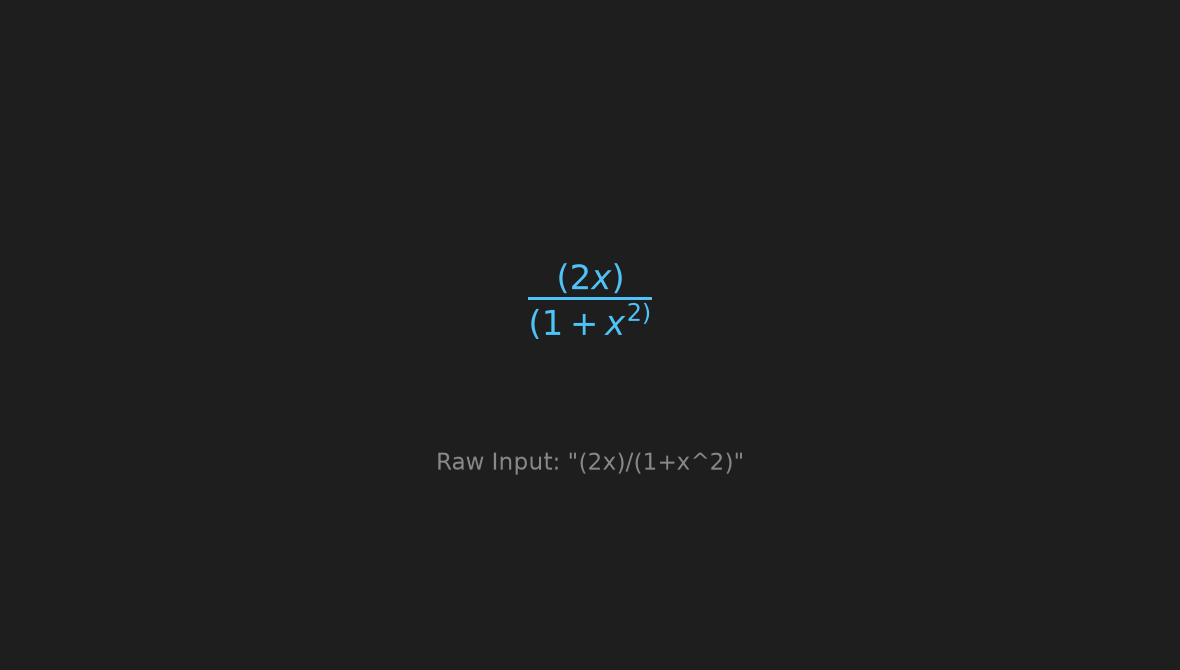

In [3]:
%gui qt6

import sys
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
from PyQt6.QtWidgets import (QApplication, QMainWindow, QVBoxLayout, 
                             QHBoxLayout, QWidget, QLabel, QLineEdit)
from PyQt6.QtCore import Qt

def parse_to_latex(raw_str: str, cursor_pos: int = -1) -> str:
    """
    사용자가 입력한 문자열을 LaTeX 문법으로 변환하는 파서 (중첩 괄호 지원)
    1. e^sin(2x+1) 또는 e^(sin(2x+1)) 처럼 지수 내 중첩 괄호 완전 파싱
    2. 입력창 커서 위치(cursor_pos)에 시각적 커서({\mathbf{\mid}}) 표시
    """
    # 1. 커서 위치에 임시 구분자 '│' 텍스트 삽입
    if 0 <= cursor_pos <= len(raw_str):
        s_with_cursor = raw_str[:cursor_pos] + "│" + raw_str[cursor_pos:]
    else:
        s_with_cursor = raw_str

    s = s_with_cursor.strip()
    if not s:
        return r"{\mathbf{\mid}}" if cursor_pos >= 0 else ""

    # 2. 커서 기호를 LaTeX용 굵은 수직선 기호로 대체
    CURSOR_MARK = r"{\mathbf{\mid}}"
    s = s.replace("│", CURSOR_MARK)

    # 3. 삼각함수 및 주요 대수함수 정규화 (sin -> \sin, log -> \log 등)
    math_funcs = ['sin', 'cos', 'tan', 'log', 'ln', 'lim', 'exp']
    for func in math_funcs:
        s = re.sub(rf'(?<!\\)\b{func}\b', rf'\\{func}', s)

    # 4. 미분 프라임(') 기호 처리
    s = s.replace("'", r"^{\prime}")

    # 5. 지수(^) 및 아래첨자(_) 처리 (중첩 괄호 파싱 로직)
    # ^( ... ) 형태에서 괄호 짝을 맞춰 가장 바깥 괄호까지 지수로 묶어줌
    def replace_nested_pow(match):
        expr = match.group(1)
        return f"^{{{expr}}}"

    # 괄호가 있는 지수: ^(...) 및 ^(...) 내부 중첩 괄호 처리
    # 예: e^(sin(2x+1)) -> e^{\sin(2x+1)}
    s = re.sub(r'\^\((.*?)\)(?=\s|$|[^)]*$)', r'^{\1}', s)
    
    # 괄호가 없는 일반 지수 연속 문자열 상주 처리
    # e^sin(2x+1) 형태로 입력해도 sin(2x+1) 전체가 지수 위로 올라감
    s = re.sub(r'\^([a-zA-C0-9_+\-*=' + re.escape(CURSOR_MARK) + r'\\\(\)]+)', r'^{\1}', s)
    s = re.sub(r'\_([a-zA-C0-9_+\-*=' + re.escape(CURSOR_MARK) + r'\\\(\)]+)', r'_{\1}', s)

    # 6. 분수 '/' 처리: A/B -> \frac{A}{B}
    frac_pattern = r'(\([^()]+\)|[a-zA-C0-9_^\'+\-*=' + re.escape(CURSOR_MARK) + r'\\\(\)]+)\/(\([^()]+\)|[a-zA-C0-9_^\'+\-*=' + re.escape(CURSOR_MARK) + r'\\\(\)]+)'
    while re.search(frac_pattern, s):
        s = re.sub(frac_pattern, r'\\frac{\1}{\2}', s)

    # 불필요한 이중 괄호 및 문법 정리
    s = s.replace(r'(\frac', r'\frac').replace(r'})', r'}')

    return s

class RealtimeLatexInputApp(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle("CalcTech - Realtime Math Parser & LaTeX Renderer")
        self.setGeometry(100, 100, 1000, 650)

        # 모던 다크 테마 QSS 스타일시트
        self.setStyleSheet("""
            QMainWindow { background-color: #1e1e1e; }
            QLabel {
                color: #ffffff;
                font-family: 'Segoe UI', sans-serif;
                font-size: 14px;
            }
            QLineEdit {
                background-color: #252526;
                color: #4fc3f7;
                border: 2px solid #007acc;
                border-radius: 6px;
                padding: 8px 12px;
                font-size: 16px;
                font-weight: bold;
                font-family: 'Consolas', monospace;
            }
            QLineEdit:focus {
                border-color: #0098ff;
            }
        """)

        main_widget = QWidget()
        self.setCentralWidget(main_widget)
        main_layout = QVBoxLayout(main_widget)
        main_layout.setContentsMargins(15, 15, 15, 15)

        # 1. 수식 입력창 UI
        input_layout = QHBoxLayout()
        input_label = QLabel("수식 입력:")
        input_label.setStyleSheet("font-size: 16px; font-weight: bold;")
        
        # 기본 입력값 설정 (지오지브라 스타일 수식)
        self.formula_input = QLineEdit()
        self.formula_input.setPlaceholderText("예: (2x+1)/(x^2+1), log_2(x), f'(x) = sin(x)/x")
        self.formula_input.setText("(2x)/(1+x^2)")  # 기본 예시 수식
        self.formula_input.textChanged.connect(self.update_canvas)

        input_layout.addWidget(input_label)
        input_layout.addWidget(self.formula_input)
        main_layout.addLayout(input_layout)

        # 2. 변환된 LaTeX 문자열 실시간 디버그 표시 레이블
        self.latex_debug_label = QLabel("LaTeX Code: ")
        self.latex_debug_label.setStyleSheet("color: #aaaaaa; font-family: 'Consolas'; font-size: 13px;")
        main_layout.addWidget(self.latex_debug_label)

        # 3. Matplotlib 캔버스
        plt.style.use('dark_background')
        self.fig, self.ax = plt.subplots(facecolor='#1e1e1e')
        self.ax.set_facecolor('#252526')
        self.canvas = FigureCanvas(self.fig)
        main_layout.addWidget(self.canvas, stretch=1)

        # 초기 렌더링
        self.update_canvas(self.formula_input.text())

    def update_canvas(self, raw_text):
        """입력창 텍스트가 바뀔 때마다 파싱 후 Matplotlib 캔버스에 수식 실시간 렌더링"""
        latex_str = parse_to_latex(raw_text)
        self.latex_debug_label.setText(f"Parsed LaTeX: ${latex_str}$")

        self.ax.clear()

        # 수식을 화면 중앙에 커다랗고 예쁘게 LaTeX 수식으로 렌더링
        if latex_str:
            try:
                # Matplotlib 내장 TeX 렌더러 활용
                display_tex = f"${latex_str}$"
                self.ax.text(0.5, 0.55, display_tex, fontsize=28, color='#4fc3f7',
                             ha='center', va='center', transform=self.ax.transAxes)
                
                # 원본 입력값도 아래에 작게 함께 표시
                self.ax.text(0.5, 0.3, f"Raw Input: \"{raw_text}\"", fontsize=13, color='#888888',
                             ha='center', va='center', transform=self.ax.transAxes)
            except Exception as e:
                # 수식 문법이 중간에 깨졌을 때 예외 처리
                self.ax.text(0.5, 0.5, "Invalid Math Syntax...", fontsize=18, color='#ff5252',
                             ha='center', va='center', transform=self.ax.transAxes)

        # 축과 그리드 숨기기 (수식 프리뷰 전용 모드)
        self.ax.axis('off')
        self.fig.tight_layout()
        self.canvas.draw()

# 주피터 환경 실행
app = QApplication.instance()
if app is None:
    app = QApplication(sys.argv)

window = RealtimeLatexInputApp()
window.show()

In [ ]:
#